In [1]:
#%matplotlib 

In [2]:
import argparse
import os
import random
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from  IPython.display import HTML

# set random seed for reproducibility
manualSeed = 999

print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
torch.use_deterministic_algorithms(True)  # Needed for reproducible results

Random Seed:  999


### Create the dataset

In [3]:
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        self.all_img_paths = [
            entry.path
            for entry in os.scandir(root_dir_path)
            if entry.is_file()
            and entry.name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]

        with Image.open(img_path) as image:
            img = image.convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [4]:
root_dir_path = "/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178),  # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) #[-1,1]
])

loaded 202599 images


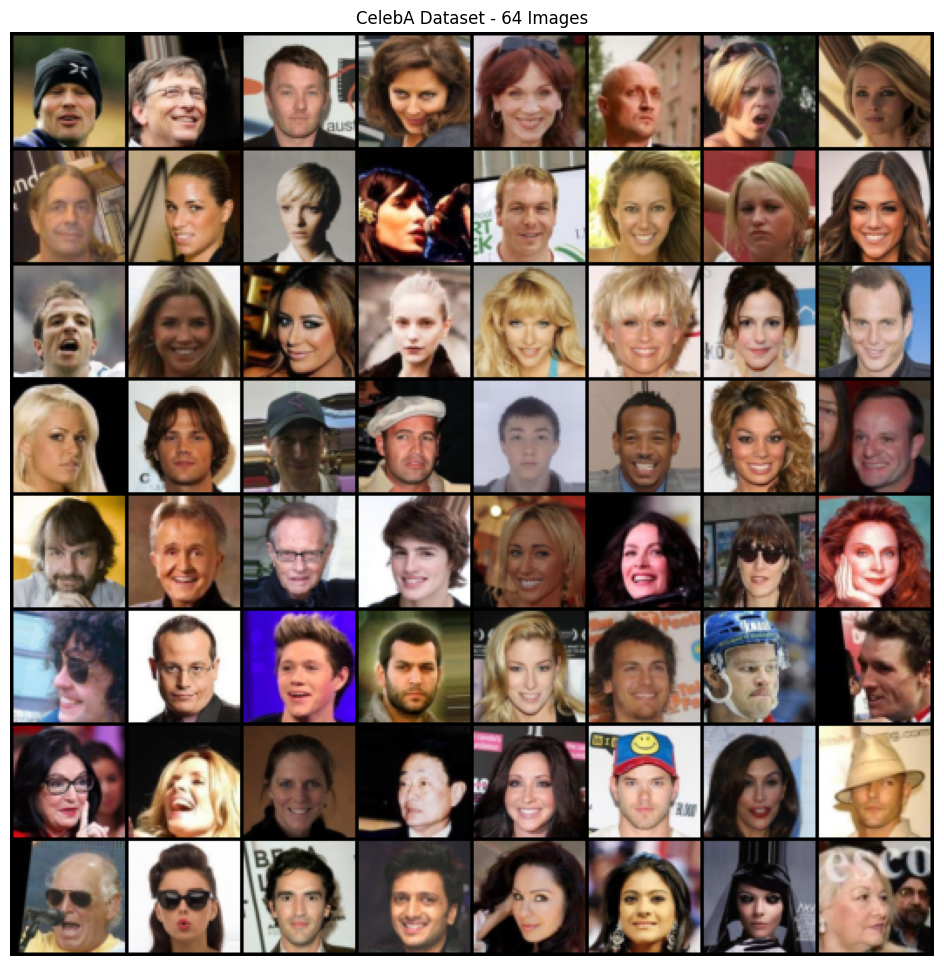

In [5]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

# Create the dataloader
dataloader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

real_batch = next(iter(dataloader))
# Select 64 images
images = real_batch[:64]

# Create grid
grid = vutils.make_grid(
    images,
    nrow=8,
    padding=2,
    normalize=True
)

# Display grid
plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("CelebA Dataset - 64 Images")
plt.show()

### Weight Initialization
all model weights shall be randomly initialized from a Normal distribution with mean=0, stdev=0.02.

In [6]:
# custom weights initialization called on ``netG`` and ``netD``
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

### Generator 

In [7]:
class Generator(nn.Module):
    def __init__(self, z=100, img_channels=3, ngf=64):
        super(Generator, self).__init__()
    
        self.main = nn.Sequential(
            nn.ConvTranspose2d( z, ngf * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. ``(ngf*8) x 4 x 4``
            
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. ``(ngf*4) x 8 x 8``
            
            nn.ConvTranspose2d( ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. ``(ngf*2) x 16 x 16``
            
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. ``(ngf) x 32 x 32``
            
            nn.ConvTranspose2d( ngf, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()
            # state size. ``3 x 64 x 64``
        )

    def forward(self, z):
        return self.main(z)

### Discriminator

In [8]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3,  ndf=64):
        super(Discriminator, self).__init__()
    
        self.main = nn.Sequential(
            # input is ``3 x 64 x 64``
            nn.Conv2d(img_channels, ndf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf) x 32 x 32``
            
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf*2) x 16 x 16``
            
            nn.Conv2d( ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ngf*4) x 8 x 8``
            
            nn.Conv2d( ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ``(ndf) x 4 x 4``
            
            nn.Conv2d( ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.main(z)

In [9]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is cuda


In [10]:
# Create the generator
netG = Generator().to(device)
# Apply the ``weights_init`` function to randomly initialize all weights
#  to ``mean=0``, ``stdev=0.02``.
netG.apply(weights_init)
print(netG)

# Create the Discriminator
netD = Discriminator().to(device)
# Apply the ``weights_init`` function to randomly initialize all weights
# like this: ``to mean=0, stdev=0.2``.
netD.apply(weights_init)
print(netD)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


### Loss Functions and Optimizers

In [11]:
# Initialize the ``BCELoss`` function
criterion = nn.BCELoss()

fixed_noise = torch.randn(16, 100, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.

# Setup Adam optimizers for both G and D
optimizerD = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))

### Training

In [12]:
def train(netG, netD, dataloader, checkpoint_path="/kaggle/working/checkpoints/gan_checkpoint.pth", resume=False):
    # Lists to keep track of progress
    G_losses = []
    D_losses = []
    start_epoch = 1
    if resume:
        checkpoint = torch.load("/kaggle/input/models/itzmohit06/checkpoints/pytorch/default/1/gan_checkpoint.pth", map_location=device, weights_only=True)
        netG.load_state_dict(checkpoint['generator_state_dict'])
        netD.load_state_dict(checkpoint['discriminator_state_dict'])
    
        optimizerG.load_state_dict(checkpoint['optimizerG_state_dict'])
        optimizerD.load_state_dict(checkpoint['optimizerD_state_dict'])
        
        start_epoch = checkpoint["epoch"] + 1
        # Restore previous losses
        G_losses = checkpoint['G_losses']
        D_losses = checkpoint['D_losses']

    epoch = start_epoch
    print("Starting Training Loop...")
    # For each epoch
    while True:
        # For each batch in the dataloader
        for i, data in enumerate(dataloader):
    
            ############################
            # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
            ###########################
            ## Train with all-real batch
            netD.zero_grad()
            # Format batch
            real_cpu = data.to(device)
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
            # Forward pass real batch through D
            output = netD(real_cpu).view(-1)
            # Calculate loss on all-real batch
            errD_real = criterion(output, label)
            # Calculate gradients for D in backward pass
            errD_real.backward()
            D_x = output.mean().item()
    
            ## Train with all-fake batch
            # Generate batch of latent vectors
            noise = torch.randn(b_size, 100, 1, 1, device=device)
            # Generate fake image batch with G
            fake = netG(noise)
            label.fill_(fake_label)
            # Classify all fake batch with D
            output = netD(fake.detach()).view(-1)
            # Calculate D's loss on the all-fake batch
            errD_fake = criterion(output, label)
            # Calculate the gradients for this batch, accumulated (summed) with previous gradients
            errD_fake.backward()
            D_G_z1 = output.mean().item()
            # Compute error of D as sum over the fake and the real batches
            errD = errD_real + errD_fake
            # Update D
            optimizerD.step()
    
            ############################
            # (2) Update G network: maximize log(D(G(z)))
            ###########################
            netG.zero_grad()
            label.fill_(real_label)  # fake labels are real for generator cost
            # Since we just updated D, perform another forward pass of all-fake batch through D
            output = netD(fake).view(-1)
            # Calculate G's loss based on this output
            errG = criterion(output, label)
            # Calculate gradients for G
            errG.backward()
            D_G_z2 = output.mean().item()
            # Update G
            optimizerG.step()
    
            # Output training stats
            if i % 50 == 0:
                print(
                    f'epoch:[{epoch}] [batch:{i+1}/{len(dataloader)}]\t'
                    f'Loss_D: {errD.item():.4f}\t'
                    f'Loss_G: {errG.item():.4f}\t'
                    f'D(x): {D_x:.4f}\t'
                    f'D(G(z)): {D_G_z1:.4f} / {D_G_z2:.4f}')
                
            # Save Losses for plotting later
            G_losses.append(errG.item())
            D_losses.append(errD.item())
            
        
        # Save training state after each completed epoch so training can be resumed.
        checkpoint_dir = os.path.dirname(checkpoint_path)
        if checkpoint_dir:
            os.makedirs(checkpoint_dir, exist_ok=True)
        torch.save({
            "epoch": epoch,
            'generator_state_dict': netG.state_dict(),
            'discriminator_state_dict': netD.state_dict(),
            'optimizerG_state_dict': optimizerG.state_dict(),
            'optimizerD_state_dict': optimizerD.state_dict(),
            # Save losses
            'G_losses': G_losses,
            'D_losses': D_losses,
        }, checkpoint_path)
        save_generated_images(netG, epoch, device, fixed_noise)
        epoch += 1

In [13]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(netG, epoch, device, fixed_noise):
    was_training = netG.training
    netG.eval()

    with torch.no_grad():
        generated_imgs = netG(fixed_noise).cpu()

    if was_training:
        netG.train()

    
    grid = torchvision.utils.make_grid(
        generated_imgs,
        nrow=4,
        normalize=True
    )

    # Create output directory
    os.makedirs("outputs", exist_ok=True)

    # Save generated image
    save_path = f"outputs/epoch_{epoch:03d}.png"
    torchvision.utils.save_image(grid, save_path)

    if (epoch == 1 or epoch % 5 == 0):
        # Display generated image
        plt.figure(figsize=(8, 8))
        plt.imshow(np.transpose(grid, (1, 2, 0)))
        plt.title(f"Epoch {epoch}")
        plt.axis("off")
        plt.show()

    print(f"Generated images saved: {save_path}")

Starting Training Loop...


epoch:[32] [batch:1/1583]	Loss_D: 0.4818	Loss_G: 3.9010	D(x): 0.8355	D(G(z)): 0.1922 / 0.0390


epoch:[32] [batch:51/1583]	Loss_D: 0.4819	Loss_G: 1.0326	D(x): 0.6962	D(G(z)): 0.0283 / 0.4890


epoch:[32] [batch:101/1583]	Loss_D: 0.3335	Loss_G: 4.8416	D(x): 0.7811	D(G(z)): 0.0233 / 0.0255


epoch:[32] [batch:151/1583]	Loss_D: 0.0494	Loss_G: 5.4367	D(x): 0.9778	D(G(z)): 0.0253 / 0.0113


epoch:[32] [batch:201/1583]	Loss_D: 0.0328	Loss_G: 6.0247	D(x): 0.9910	D(G(z)): 0.0224 / 0.0064


... (122 outputs left out)

epoch:[35] [batch:1401/1583]	Loss_D: 0.0527	Loss_G: 5.1354	D(x): 0.9577	D(G(z)): 0.0079 / 0.0141


epoch:[35] [batch:1451/1583]	Loss_D: 0.0310	Loss_G: 5.9607	D(x): 0.9846	D(G(z)): 0.0144 / 0.0089


epoch:[35] [batch:1501/1583]	Loss_D: 0.0568	Loss_G: 4.3198	D(x): 0.9581	D(G(z)): 0.0123 / 0.0346


epoch:[35] [batch:1551/1583]	Loss_D: 0.0402	Loss_G: 5.3258	D(x): 0.9758	D(G(z)): 0.0100 / 0.0144


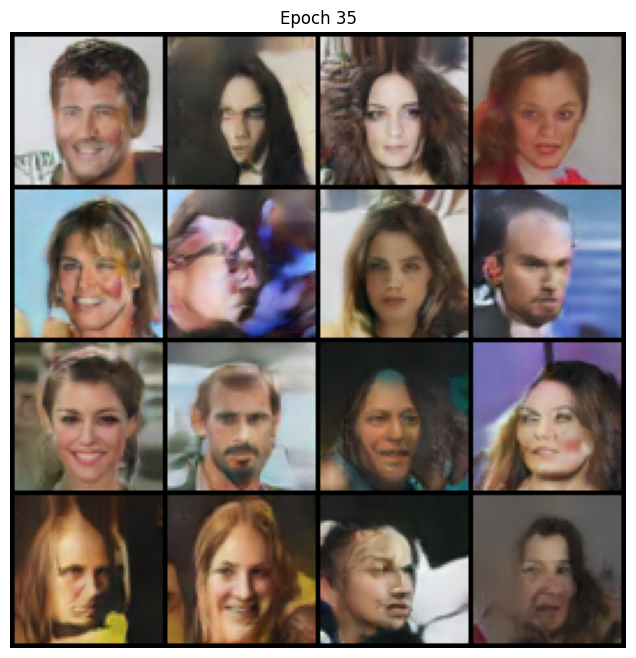

Generated images saved: outputs/epoch_035.png


epoch:[36] [batch:1/1583]	Loss_D: 0.0289	Loss_G: 5.7655	D(x): 0.9824	D(G(z)): 0.0104 / 0.0082


epoch:[36] [batch:51/1583]	Loss_D: 0.0465	Loss_G: 5.2584	D(x): 0.9789	D(G(z)): 0.0226 / 0.0157


epoch:[36] [batch:101/1583]	Loss_D: 0.0689	Loss_G: 4.1468	D(x): 0.9503	D(G(z)): 0.0129 / 0.0439


epoch:[36] [batch:151/1583]	Loss_D: 0.0205	Loss_G: 5.9765	D(x): 0.9961	D(G(z)): 0.0161 / 0.0072


epoch:[36] [batch:201/1583]	Loss_D: 0.0577	Loss_G: 5.4815	D(x): 0.9526	D(G(z)): 0.0039 / 0.0120


... (155 outputs left out)

epoch:[40] [batch:1401/1583]	Loss_D: 0.0115	Loss_G: 6.6613	D(x): 0.9943	D(G(z)): 0.0056 / 0.0038


epoch:[40] [batch:1451/1583]	Loss_D: 0.0277	Loss_G: 6.3082	D(x): 0.9806	D(G(z)): 0.0074 / 0.0064


epoch:[40] [batch:1501/1583]	Loss_D: 0.7215	Loss_G: 2.6607	D(x): 0.6503	D(G(z)): 0.0510 / 0.2088


epoch:[40] [batch:1551/1583]	Loss_D: 0.2482	Loss_G: 5.2673	D(x): 0.8968	D(G(z)): 0.0847 / 0.0128


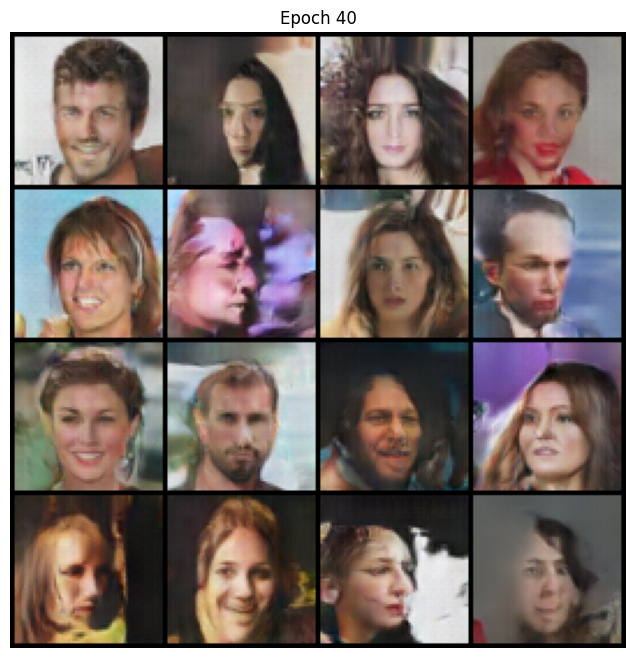

Generated images saved: outputs/epoch_040.png


epoch:[41] [batch:1/1583]	Loss_D: 0.1464	Loss_G: 5.6648	D(x): 0.9910	D(G(z)): 0.1036 / 0.0083


epoch:[41] [batch:51/1583]	Loss_D: 0.0363	Loss_G: 5.7668	D(x): 0.9905	D(G(z)): 0.0245 / 0.0094


epoch:[41] [batch:101/1583]	Loss_D: 0.0750	Loss_G: 5.4601	D(x): 0.9385	D(G(z)): 0.0069 / 0.0141


epoch:[41] [batch:151/1583]	Loss_D: 0.1914	Loss_G: 2.9876	D(x): 0.8472	D(G(z)): 0.0037 / 0.1393


epoch:[41] [batch:201/1583]	Loss_D: 0.0874	Loss_G: 5.8870	D(x): 0.9828	D(G(z)): 0.0564 / 0.0082


... (155 outputs left out)

epoch:[45] [batch:1401/1583]	Loss_D: 0.0859	Loss_G: 5.5811	D(x): 0.9910	D(G(z)): 0.0640 / 0.0082


epoch:[45] [batch:1451/1583]	Loss_D: 0.0173	Loss_G: 6.0560	D(x): 0.9945	D(G(z)): 0.0113 / 0.0076


epoch:[45] [batch:1501/1583]	Loss_D: 0.0290	Loss_G: 5.8681	D(x): 0.9949	D(G(z)): 0.0221 / 0.0079


epoch:[45] [batch:1551/1583]	Loss_D: 0.0782	Loss_G: 4.3482	D(x): 0.9406	D(G(z)): 0.0117 / 0.0325


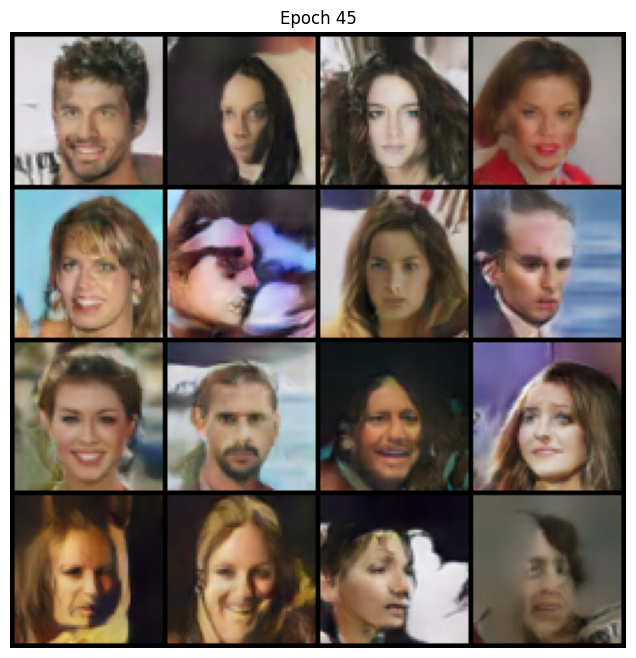

Generated images saved: outputs/epoch_045.png


epoch:[46] [batch:1/1583]	Loss_D: 0.1163	Loss_G: 4.7590	D(x): 0.9053	D(G(z)): 0.0091 / 0.0298


epoch:[46] [batch:51/1583]	Loss_D: 0.1289	Loss_G: 3.9409	D(x): 0.9125	D(G(z)): 0.0146 / 0.0511


epoch:[46] [batch:101/1583]	Loss_D: 0.0402	Loss_G: 6.0202	D(x): 0.9959	D(G(z)): 0.0333 / 0.0062


epoch:[46] [batch:151/1583]	Loss_D: 0.1542	Loss_G: 4.7642	D(x): 0.8968	D(G(z)): 0.0254 / 0.0299


epoch:[46] [batch:201/1583]	Loss_D: 0.7175	Loss_G: 2.4367	D(x): 0.6419	D(G(z)): 0.0237 / 0.1873


... (155 outputs left out)

epoch:[50] [batch:1401/1583]	Loss_D: 0.3011	Loss_G: 1.7026	D(x): 0.7831	D(G(z)): 0.0066 / 0.3091


epoch:[50] [batch:1451/1583]	Loss_D: 0.0668	Loss_G: 5.8100	D(x): 0.9719	D(G(z)): 0.0319 / 0.0104


epoch:[50] [batch:1501/1583]	Loss_D: 0.0598	Loss_G: 5.4038	D(x): 0.9843	D(G(z)): 0.0393 / 0.0113


epoch:[50] [batch:1551/1583]	Loss_D: 0.0695	Loss_G: 4.8861	D(x): 0.9562	D(G(z)): 0.0198 / 0.0222


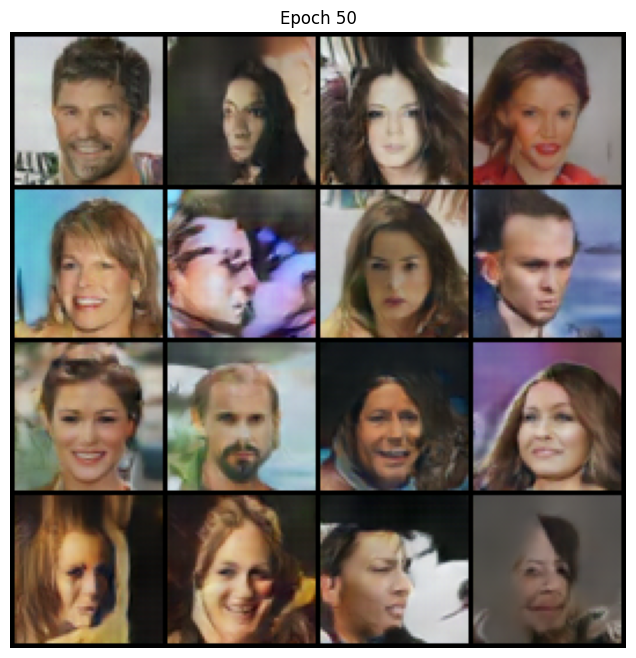

Generated images saved: outputs/epoch_050.png


epoch:[51] [batch:1/1583]	Loss_D: 0.3940	Loss_G: 5.3437	D(x): 0.9803	D(G(z)): 0.2584 / 0.0097


epoch:[51] [batch:51/1583]	Loss_D: 0.0653	Loss_G: 4.8593	D(x): 0.9668	D(G(z)): 0.0277 / 0.0209


epoch:[51] [batch:101/1583]	Loss_D: 0.0566	Loss_G: 6.3074	D(x): 0.9771	D(G(z)): 0.0301 / 0.0060


epoch:[51] [batch:151/1583]	Loss_D: 0.0205	Loss_G: 6.4660	D(x): 0.9908	D(G(z)): 0.0106 / 0.0050


epoch:[51] [batch:201/1583]	Loss_D: 0.0454	Loss_G: 5.6526	D(x): 0.9896	D(G(z)): 0.0329 / 0.0101


... (155 outputs left out)

epoch:[55] [batch:1401/1583]	Loss_D: 0.0483	Loss_G: 5.5981	D(x): 0.9729	D(G(z)): 0.0188 / 0.0135


epoch:[55] [batch:1451/1583]	Loss_D: 0.0214	Loss_G: 5.5029	D(x): 0.9983	D(G(z)): 0.0190 / 0.0132


epoch:[55] [batch:1501/1583]	Loss_D: 0.0260	Loss_G: 5.8591	D(x): 0.9822	D(G(z)): 0.0064 / 0.0099


epoch:[55] [batch:1551/1583]	Loss_D: 0.0187	Loss_G: 6.6915	D(x): 0.9900	D(G(z)): 0.0082 / 0.0059


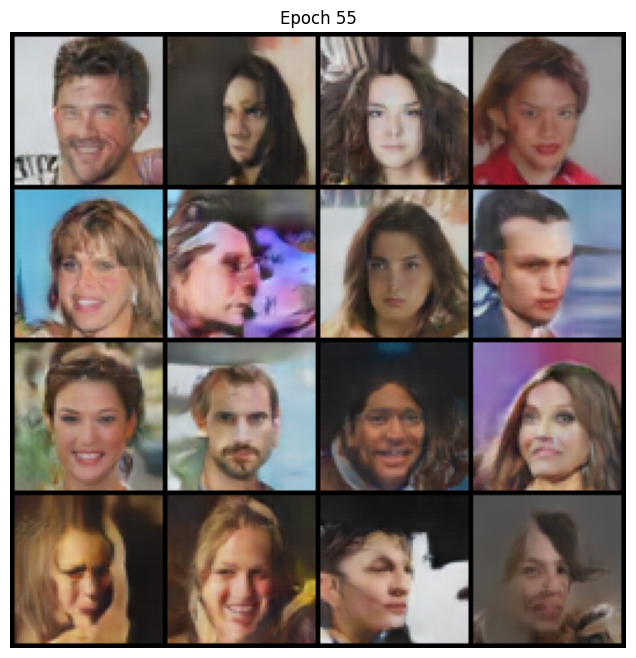

Generated images saved: outputs/epoch_055.png


epoch:[56] [batch:1/1583]	Loss_D: 0.0317	Loss_G: 6.3325	D(x): 0.9829	D(G(z)): 0.0090 / 0.0052


epoch:[56] [batch:51/1583]	Loss_D: 0.0257	Loss_G: 6.3123	D(x): 0.9779	D(G(z)): 0.0025 / 0.0054


epoch:[56] [batch:101/1583]	Loss_D: 0.0621	Loss_G: 6.0765	D(x): 0.9918	D(G(z)): 0.0441 / 0.0066


epoch:[56] [batch:151/1583]	Loss_D: 0.0637	Loss_G: 5.2803	D(x): 0.9596	D(G(z)): 0.0144 / 0.0187


epoch:[56] [batch:201/1583]	Loss_D: 0.2155	Loss_G: 3.8572	D(x): 0.8964	D(G(z)): 0.0605 / 0.0778


... (155 outputs left out)

epoch:[60] [batch:1401/1583]	Loss_D: 0.0222	Loss_G: 6.2459	D(x): 0.9864	D(G(z)): 0.0075 / 0.0088


epoch:[60] [batch:1451/1583]	Loss_D: 0.1137	Loss_G: 5.2331	D(x): 0.9283	D(G(z)): 0.0282 / 0.0230


epoch:[60] [batch:1501/1583]	Loss_D: 0.0308	Loss_G: 5.7450	D(x): 0.9851	D(G(z)): 0.0143 / 0.0108


epoch:[60] [batch:1551/1583]	Loss_D: 0.0411	Loss_G: 5.9980	D(x): 0.9915	D(G(z)): 0.0288 / 0.0080


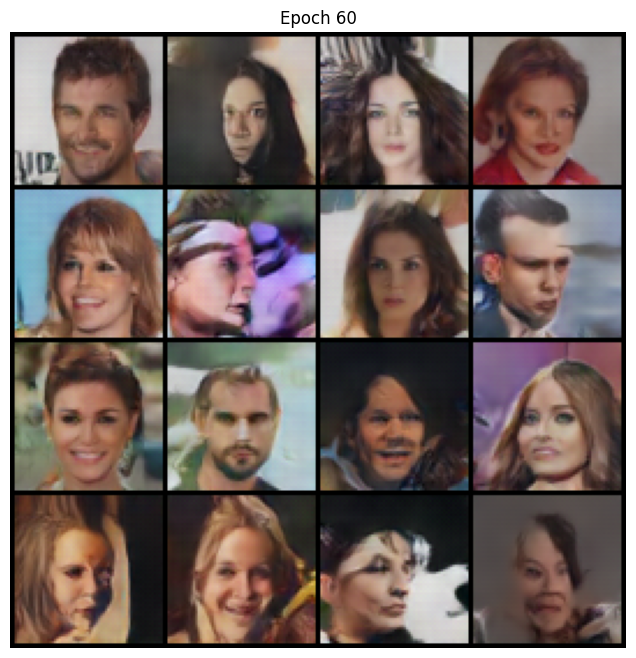

Generated images saved: outputs/epoch_060.png


epoch:[61] [batch:1/1583]	Loss_D: 0.1484	Loss_G: 7.5164	D(x): 0.9939	D(G(z)): 0.1001 / 0.0014


epoch:[61] [batch:51/1583]	Loss_D: 0.0254	Loss_G: 6.1455	D(x): 0.9948	D(G(z)): 0.0192 / 0.0070


epoch:[61] [batch:101/1583]	Loss_D: 0.0276	Loss_G: 5.9298	D(x): 0.9892	D(G(z)): 0.0158 / 0.0077


epoch:[61] [batch:151/1583]	Loss_D: 0.0127	Loss_G: 6.7219	D(x): 0.9964	D(G(z)): 0.0089 / 0.0053


epoch:[61] [batch:201/1583]	Loss_D: 0.0200	Loss_G: 6.6340	D(x): 0.9858	D(G(z)): 0.0048 / 0.0042


... (155 outputs left out)

epoch:[65] [batch:1401/1583]	Loss_D: 0.0182	Loss_G: 6.3386	D(x): 0.9954	D(G(z)): 0.0130 / 0.0065


epoch:[65] [batch:1451/1583]	Loss_D: 0.3957	Loss_G: 5.3814	D(x): 0.9441	D(G(z)): 0.2158 / 0.0099


epoch:[65] [batch:1501/1583]	Loss_D: 0.0303	Loss_G: 6.7320	D(x): 0.9870	D(G(z)): 0.0163 / 0.0055


epoch:[65] [batch:1551/1583]	Loss_D: 0.0386	Loss_G: 5.7216	D(x): 0.9776	D(G(z)): 0.0139 / 0.0099


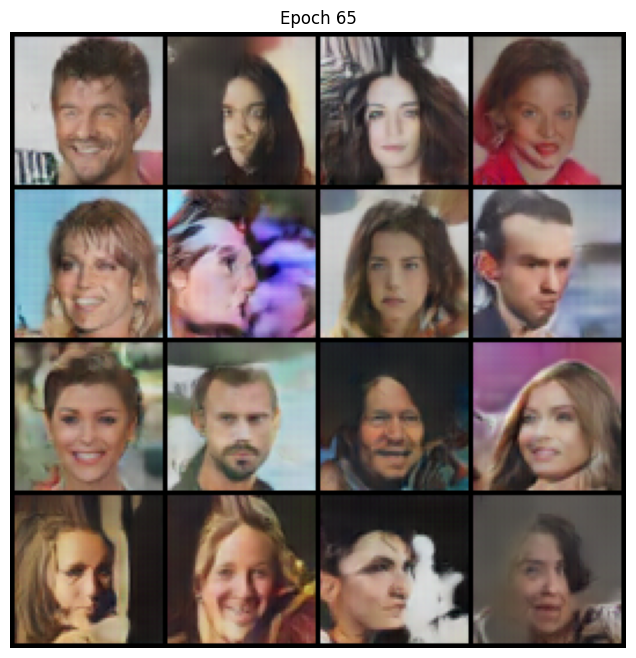

Generated images saved: outputs/epoch_065.png


epoch:[66] [batch:1/1583]	Loss_D: 0.1827	Loss_G: 4.1931	D(x): 0.9509	D(G(z)): 0.0839 / 0.0367


epoch:[66] [batch:51/1583]	Loss_D: 0.1162	Loss_G: 4.0914	D(x): 0.9130	D(G(z)): 0.0112 / 0.0561


epoch:[66] [batch:101/1583]	Loss_D: 0.0362	Loss_G: 6.2520	D(x): 0.9765	D(G(z)): 0.0113 / 0.0058


epoch:[66] [batch:151/1583]	Loss_D: 0.0445	Loss_G: 5.3409	D(x): 0.9691	D(G(z)): 0.0106 / 0.0187


epoch:[66] [batch:201/1583]	Loss_D: 0.0154	Loss_G: 7.7321	D(x): 0.9889	D(G(z)): 0.0037 / 0.0018


... (150 outputs left out)

epoch:[70] [batch:1151/1583]	Loss_D: 0.1258	Loss_G: 4.0205	D(x): 0.9082	D(G(z)): 0.0128 / 0.0562


epoch:[70] [batch:1201/1583]	Loss_D: 0.0993	Loss_G: 4.1568	D(x): 0.9369	D(G(z)): 0.0241 / 0.0434


epoch:[70] [batch:1251/1583]	Loss_D: 0.0942	Loss_G: 4.3414	D(x): 0.9279	D(G(z)): 0.0045 / 0.0439


epoch:[70] [batch:1301/1583]	Loss_D: 0.0529	Loss_G: 6.0768	D(x): 0.9876	D(G(z)): 0.0315 / 0.0085


In [14]:

train(netG, netD, dataloader, resume=True)

### Result

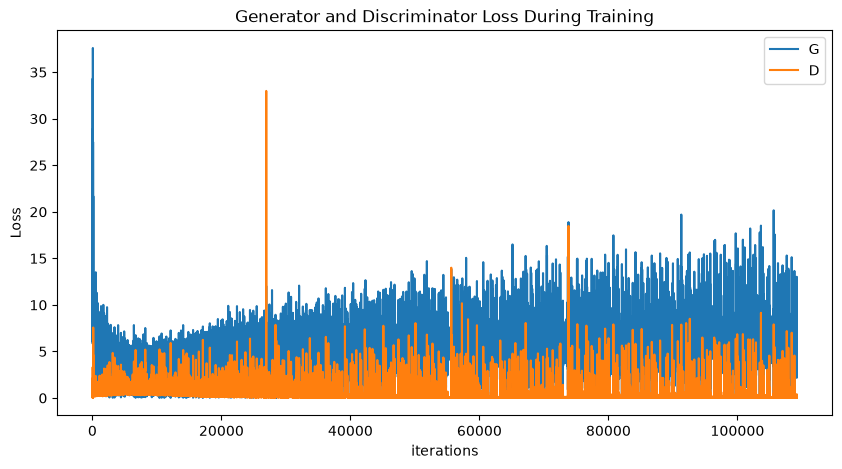

In [10]:
checkpoint = torch.load("./checkpoints/gan_checkpoint.pth",map_location="cpu", weights_only=True)    
# Restore previous losses
G_losses = checkpoint['G_losses']
D_losses = checkpoint['D_losses']

plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses,label="G")
plt.plot(D_losses,label="D")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

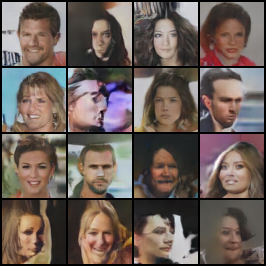

In [15]:
from IPython.display import Image, display

display(Image(filename="outputs/epoch_069.png"))